# Pós Ciência dos Dados - Aplicações de Aprendizado de Máquina

## Atividade 1

Utilize as células a seguir como base para carregar as informações, e a partir da última célula desse modelo, desenvolva seu raciocínio e como seria a abordagem do seu grupo para esse problema. *Não altere as células apresentadas aqui para não danificar a leitura dos dados.*

Os dados estão mascarados, mas basicamente, a variável *y* aponta para quando uma determinada ação vai subir ou vai descer na bolsa.

---

**Nome dos integrantes**

Aluno 1:

Aluno 2:

Aluno 3:

Aluno 4:

---

Lembrem-se, o grupo deve ter no máximo 4 integrantes por grupo, e deverão ser entregues até **08/02 às 23h59** esse notebook preenchido com os experimentos realizados e as conclusões observadas, além de um PDF com 5 slides para o grupo apresentar em 3 minutos para o restante da sala.

In [4]:
import pandas as pd
import numpy as np
from sklearn import metrics, preprocessing, linear_model

# deixa fixo o fator de aleatoriedade
np.random.seed(0)

In [5]:
# carrega os dados
data = pd.read_csv('training_data.csv', header=0)

data = data.drop([
    'id', 'era', 'data_type', 'target_charles', 'target_elizabeth',
    'target_jordan', 'target_ken', 'target_frank', 'target_hillary'],axis=1)

In [6]:
data.head()
#print(data.shape)

,feature1,feature2,feature3,feature4,feature5,feature6,feature7,feature8,feature9,feature10,...,feature42,feature43,feature44,feature45,feature46,feature47,feature48,feature49,feature50,target_bernie
0,0.54836,0.31077,0.37524,0.49490,0.53217,0.48388,0.50220,0.59506,0.55422,0.48578,...,0.32205,0.53407,0.46254,0.56658,0.46022,0.63760,0.55239,0.64054,0.52182,1
1,0.34712,0.40275,0.42747,0.44006,0.47866,0.44055,0.59182,0.68856,0.56543,0.57715,...,0.46215,0.48303,0.35919,0.58709,0.55369,0.64628,0.46029,0.62941,0.55010,1
2,0.50871,0.48639,0.47544,0.40306,0.53436,0.64028,0.51420,0.63232,0.62101,0.48065,...,0.50243,0.51624,0.48028,0.73195,0.42444,0.43228,0.40596,0.54731,0.39061,0
3,0.61363,0.40268,0.53779,0.37045,0.58711,0.59900,0.62428,0.73602,0.43887,0.28383,...,0.54347,0.46995,0.60385,0.56471,0.51203,0.35597,0.53878,0.47776,0.36835,0
4,0.30704,0.47273,0.54495,0.48692,0.47348,0.34695,0.41506,0.61225,0.56853,0.44104,...,0.54050,0.39448,0.29495,0.61935,0.45651,0.53768,0.46431,0.49482,0.60452,1


In [7]:
data.isna().sum()
#data.isin({0}).sum()

feature1         0
feature2         0
feature3         0
feature4         0
feature5         0
feature6         0
feature7         0
feature8         0
feature9         0
feature10        0
feature11        0
feature12        0
feature13        0
feature14        0
feature15        0
feature16        0
feature17        0
feature18        0
feature19        0
feature20        0
feature21        0
feature22        0
feature23        0
feature24        0
feature25        0
feature26        0
feature27        0
feature28        0
feature29        0
feature30        0
feature31        0
feature32        0
feature33        0
feature34        0
feature35        0
feature36        0
feature37        0
feature38        0
feature39        0
feature40        0
feature41        0
feature42        0
feature43        0
feature44        0
feature45        0
feature46        0
feature47        0
feature48        0
feature49        0
feature50        0
target_bernie    0
dtype: int64

In [5]:
# transforma o CSV em numpy
features = [f for f in list(data) if "feature" in f]
X = data[features]
y = data['target_bernie']

In [6]:
# exibe quantidade de amostras e atributos
print(X.shape)
print(y.shape)

(502732, 50)
(502732,)


In [7]:
# a partir daqui é com você...
# 1) separe 30% dos dados para teste e utilize os outros 70% como achar melhor
# 2) lembre-se de aplicar os conceitos vistos em aula

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

# separando o conjunto de treino em validação também
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.30, random_state=42)

In [8]:
print(X_train.shape)
print(y_train.shape)
print(X_val.shape)
print(X_val.shape)

(246338, 50)
(246338,)
(105574, 50)
(105574, 50)


In [24]:
# treinando o modelo 
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)#instância do KNN
knn.fit(X_train, y_train)

# avaliando o modelo
from sklearn.metrics import accuracy_score
y_pred = knn.predict(X_val)
accuracy_score(y_val, y_pred)

0.5027847765548336

Text(0.5,1,'PCA of FEATURES dataset')

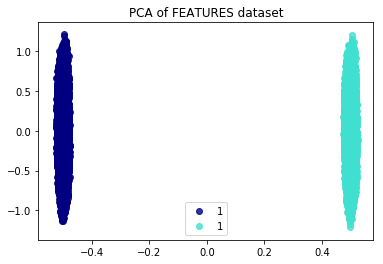

In [11]:
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_r = pca.fit_transform(data)

colors = ['navy', 'turquoise']
for color, i, target_bernie in zip(colors, [0, 1], data.target_bernie):
    plt.scatter(X_r[y == i, 0], X_r[y == i, 1], color=color, alpha=.8, label=target_bernie)
plt.legend(loc='best', shadow=False, scatterpoints=1)
plt.title('PCA of FEATURES dataset')

In [21]:
# embaralhando os dados várias vezes e re-executando o experimento
import numpy as np
from sklearn.model_selection import ShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
ss = ShuffleSplit(n_splits=2, test_size=0.3, uy-
                  random_state=0) # 5 execuções diferentes(5 valores aleatórios) com 20% dos dados para teste
#o ShuffleSplit sempre vai trazer a mesmas 5 divisões, uma diferente da outra, mas sempre essas
acc = []
for train_index, test_index in ss.split(data):#cada vez que passar no for ele passa os índices de treino e de teste 
    knn = KNeighborsClassifier(n_neighbors = 1)
    knn.fit(data[train_index],y[train_index])
    y_pred = knn.predict(data[test_index])
    acc.append(accuracy_score(y_pred,y[test_index]))

acc = np.asarray(acc) # converte pra numpy pra ficar mais simples de usar média e desvio padrão
print('Accuracy - %.2f +- %.2f' % (acc.mean() * 100, acc.std() * 100))#média e desvio padrão

KeyError: '[ 13809 206515 206494 ... 435829 305711 461484] not in index'

In [ ]:
best_model = None
best_accuracy = 0

for k in [1,2,3,4,5]:

    knn = KNeighborsClassifier(n_neighbors = k) # a cada passo, o parâmetro assume um valor
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    print('K:', k, '- ACC:', acc)
    
    if acc > best_accuracy:
        best_model = knn
        best_accuracy = acc
        
y_pred = best_model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print()
print('Melhor modelo:')
print('K:', best_model.get_params()['n_neighbors'], '- ACC:', acc * 100) #corrigir

In [ ]:
data_gs, data_cv, target_gs, target_cv = train_test_split(data, y, test_size=0.95, random_state=42, stratify=y)
import datetime as dt
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S")
pipeline = Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier())])

# utiliza-se GridSearchCV para achar os melhores parâmetros
from sklearn.model_selection import GridSearchCV#ao invéz do for K in [1,2,3,4,5]
parameters = {'clf__n_neighbors': [1,2,3,4,5], 'clf__weights' : ['uniform','distance'] } # quais parâmetros(de K e de classificador) e quais valores serão testados
clf = GridSearchCV(pipeline, parameters, cv=3, iid=False) # clf vai armazenar qual foi a melhor configuração
clf.fit(data_gs,target_gs)

print(clf.best_estimator_)
dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S")

# utilizando validação cruzada para avaliar o modelo
scores = cross_val_score(clf, data_cv, target_cv, cv=5)

print('Accuracy - %.2f +- %.2f' % (scores.mean() * 100, scores.std() * 100))

dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S")

2019-02-01 09:30:37.957484
Pipeline(memory=None,
     steps=[('scaler', StandardScaler(copy=True, with_mean=True, with_std=True)), ('clf', KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
           metric_params=None, n_jobs=1, n_neighbors=5, p=2,
           weights='uniform'))])
